# INSTRUCCIONES

## OBJETIVOS

Desarrollar competencias básicas para:

1. Modelar problemas para ser resueltos como sistemas basados en conocimiento.
2. Implementar algoritmos de inferencia para lógica proposicional con cláusulas definidas (forward, backward).
3. Construir un **subsistema de desarrollo** y un **subsistema de consulta** que permitan construir el conocimiento, usarlo y explicar el *cómo* de sus conclusiones.
4. Adquirir conocimiento a partir de ejemplos con **árboles de decisión** y traducirlo a reglas de una base de conocimiento.
5. Resolver problemas usando lógica proposicional, los algoritmos de inferencia implementados y árboles de decisión.

## ENTREGABLE

*Reglas para el envío de los entregables:*

- **Forma de envío:**

  Este laboratorio se debe enviar únicamente a través de la plataforma [Moodle](https://campusvirtual.escuelaing.edu.co/moodle/) en la actividad definida.

- **Archivo de entrega:**

  Incluyan en un archivo `.zip` los archivos correspondientes al laboratorio, revise **[How to cite in Jupyter Notebooks](https://gist.github.com/ELS4NTA/2c188b3b7300a726e60d71a58a55f740)** para citar cualquier recurso utilizado y ver la estructura del proyecto.

- **Nomenclatura para nombrar el archivo de entrega:**

  El archivo deberá ser renombrado en mayúsculas con el siguiente formato: `L05-{color_grupo}-IAIA-{semestre_academico}.zip`

  Ejemplos:
  ```
  L05-AZUL-IAIA-2026-2.zip
  L05-ROJO-IAIA-2026-2.zip
  ```

Revise cuando lo requiera <a href="https://aima.cs.berkeley.edu/">(Russell & Norvig, 2021, cap. 7 y sec. 19.3) <cite data-cite="russell2021artificial"></cite></a>

# I. CONSTRUCCIÓN

Implementarán un **Sistema Basado en Conocimiento (SBC)** que razona con **lógica proposicional** usando **cláusulas definidas de Horn** en forma de implicación:

$$Proposition_1 \land \cdots \land Proposition_n \Rightarrow Proposition$$

donde cada proposición puede tomar **tres valores**: verdadero (`YES`), falso (`NO`) o desconocido (`UNKNOWN`).

Trabajar con tres valores permite que el motor razone aun cuando la información del mundo esté incompleta.

El motor contiene:

- **Base de conocimiento (KB):** el conocimiento *estable* del contexto. Contiene:
    1. Las **proposiciones** del dominio.
    2. Las **reglas** que relacionan las proposiciones.

- **Base de hechos (FB):** el conocimiento *particular* del caso que se está resolviendo. Cada hecho guarda la proposición, su **valor conocido** (`YES`, `NO` o `UNKNOWN`) y quién lo aportó: el **usuario**, o la **regla** que lo dedujo.

El SBC se organiza en **dos subsistemas**:

- **Subsistema de desarrollo**: permite *construir* el conocimiento; lo usa el experto.
- **Subsistema de consulta**: permite *usar* el conocimiento para deducir, responder y explicar; lo usa el usuario.

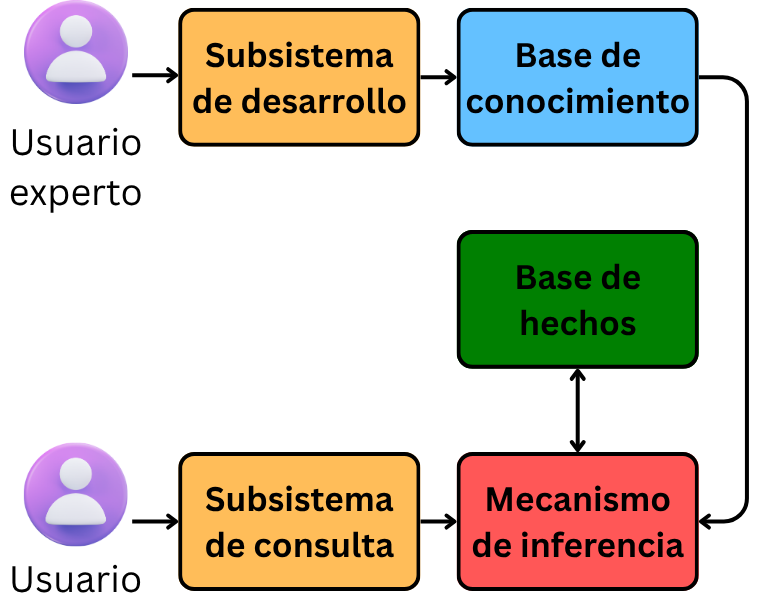

Al final del laboratorio construirán el puente con el aprendizaje: **aprender un árbol de decisión** con una librería de ML y **traducirlo a reglas** que el mismo motor pueda usar.

## A. EXPLICACIÓN

### Proposición atómica

Una **proposición atómica** es una afirmación declarativa que puede ser verdadera o falsa. En nuestro motor la representaremos con dos componentes:

| Componente | Descripción |
|---|---|
| `symbol` | identificador con **nombre semántico** (variable) |
| `meaning` | texto en lenguaje natural |

### Valor de una proposición

Usaremos la siguiente representación:

| Valor | Significado |
|---|---|
| `YES` | la proposición se cumple (verdadera) |
| `NO`  | la proposición no se cumple (falsa) |
| `UNKNOWN` | **se sabe que no se sabe** su valor |

El valor `UNKNOWN`: *no* significa simplemente *"no se sabe"*; significa que el motor ya intentó determinarlo, no pudo, y **así lo registra para no volver a preguntar**.

Para ver la diferencia, considere una proposición `p`:

- Si `p` **no está** en la FB → el motor *no sabe su valor*. Cuando llegue el momento, intentará deducirlo o preguntárselo al usuario.
- Si `p` **está en la FB con valor `UNKNOWN`** → el motor ya lo intentó y el resultado fue *no sé*. Esta entrada sirve como **memoria**: si alguien vuelve a pedir `p`, el motor responde `UNKNOWN` sin repetir el trabajo ni preguntar otra vez al usuario.

### Regla

Una **regla** es una cláusula definida de Horn con la forma $(P_1 \land \dots \land P_n) \Rightarrow Q$, con **un único** consecuente positivo.

Además, en nuestro motor cada regla lleva un **identificador**. El identificador se usa para dos cosas:

1. **Referenciar la regla** dentro de la KB para buscarla o actualizarla.
2. **Rastrear el origen de un hecho deducido**: cuando una regla deduce un hecho, ese hecho queda en la FB con el identificador de la regla como origen, lo que permitirá luego **explicar el *cómo*** de la conclusión.

Una regla debe poder **mostrarse en lenguaje natural**, es decir, imprimirse recombinando el `meaning` de sus antecedentes y consecuente. Esto es importante porque la interfaz usa esta forma legible para comunicarle al usuario qué reglas hay en la KB y cómo se llegó a una conclusión.

### Base de conocimiento (KB)

La KB representa el conocimiento **estable** del dominio y contiene **dos cosas**:

- El conjunto de **proposiciones** (`TAtom`) del dominio.
- El conjunto de **reglas** (`TRule`) que las relacionan.

Cuando se adiciona una regla, el motor debe **validar** que todas las proposiciones que aparecen en ella (antecedentes y consecuente) ya estén registradas en la KB. Así se evita construir reglas sobre proposiciones no declaradas.

### Base de hechos (FB)

La FB representa el conocimiento **particular** del caso. Cada entrada es un hecho: una proposición, su **valor conocido** y su **origen**. Los valores pueden haberse **dado por el usuario** o haber sido **deducidos por una regla**. Guardar el origen es lo que permite después **explicar el cómo** de una conclusión.

### Ejemplos

**Proposiciones atómicas**

| `symbol` | `meaning` |
|---|---|
| `tiene_pelo` | el animal tiene pelo |
| `come_carne` | el animal come carne |
| `es_mamifero_carnivoro` | el animal es un mamífero carnívoro |

**Regla**

`R1: tiene_pelo` $\land$ `come_carne` $\Rightarrow$ `es_mamifero_carnivoro`

En lenguaje natural: `R1: el animal tiene pelo` $\land$ `el animal come carne` $\Rightarrow$ `el animal es un mamífero carnívoro`.

**Base de conocimiento**

Proposiciones `{tiene_pelo, come_carne, es_mamifero_carnivoro}` y reglas `{R1}`.

**Base de hechos**

| Momento | Hechos en la FB |
|---|---|
| Inicial | `tiene_pelo = YES (user)`, `come_carne = YES (user)` |
| Tras la inferencia hacia adelante | `tiene_pelo = YES (user)`, `come_carne = YES (user)`, `es_mamifero_carnivoro = YES (R1)` |

El origen `R1` es lo que permite explicar **cómo** se concluyó `es_mamifero_carnivoro`.

**Valor `UNKNOWN` vs. No tener valor en la FB**

- Si la FB inicial solo tuviera `tiene_pelo = YES`, `come_carne` **no estaría** en la FB: el motor intentaría deducirlo o se lo preguntaría al usuario.
- Si el usuario ya hubiera respondido *no sé*, la FB tendría `come_carne = UNKNOWN (user)`: el motor no vuelve a preguntar y `R1` ya no puede aplicarse.


## B. REPRESENTACIÓN

Modelen las estructuras de datos. Deben **probarlas** antes de continuar.

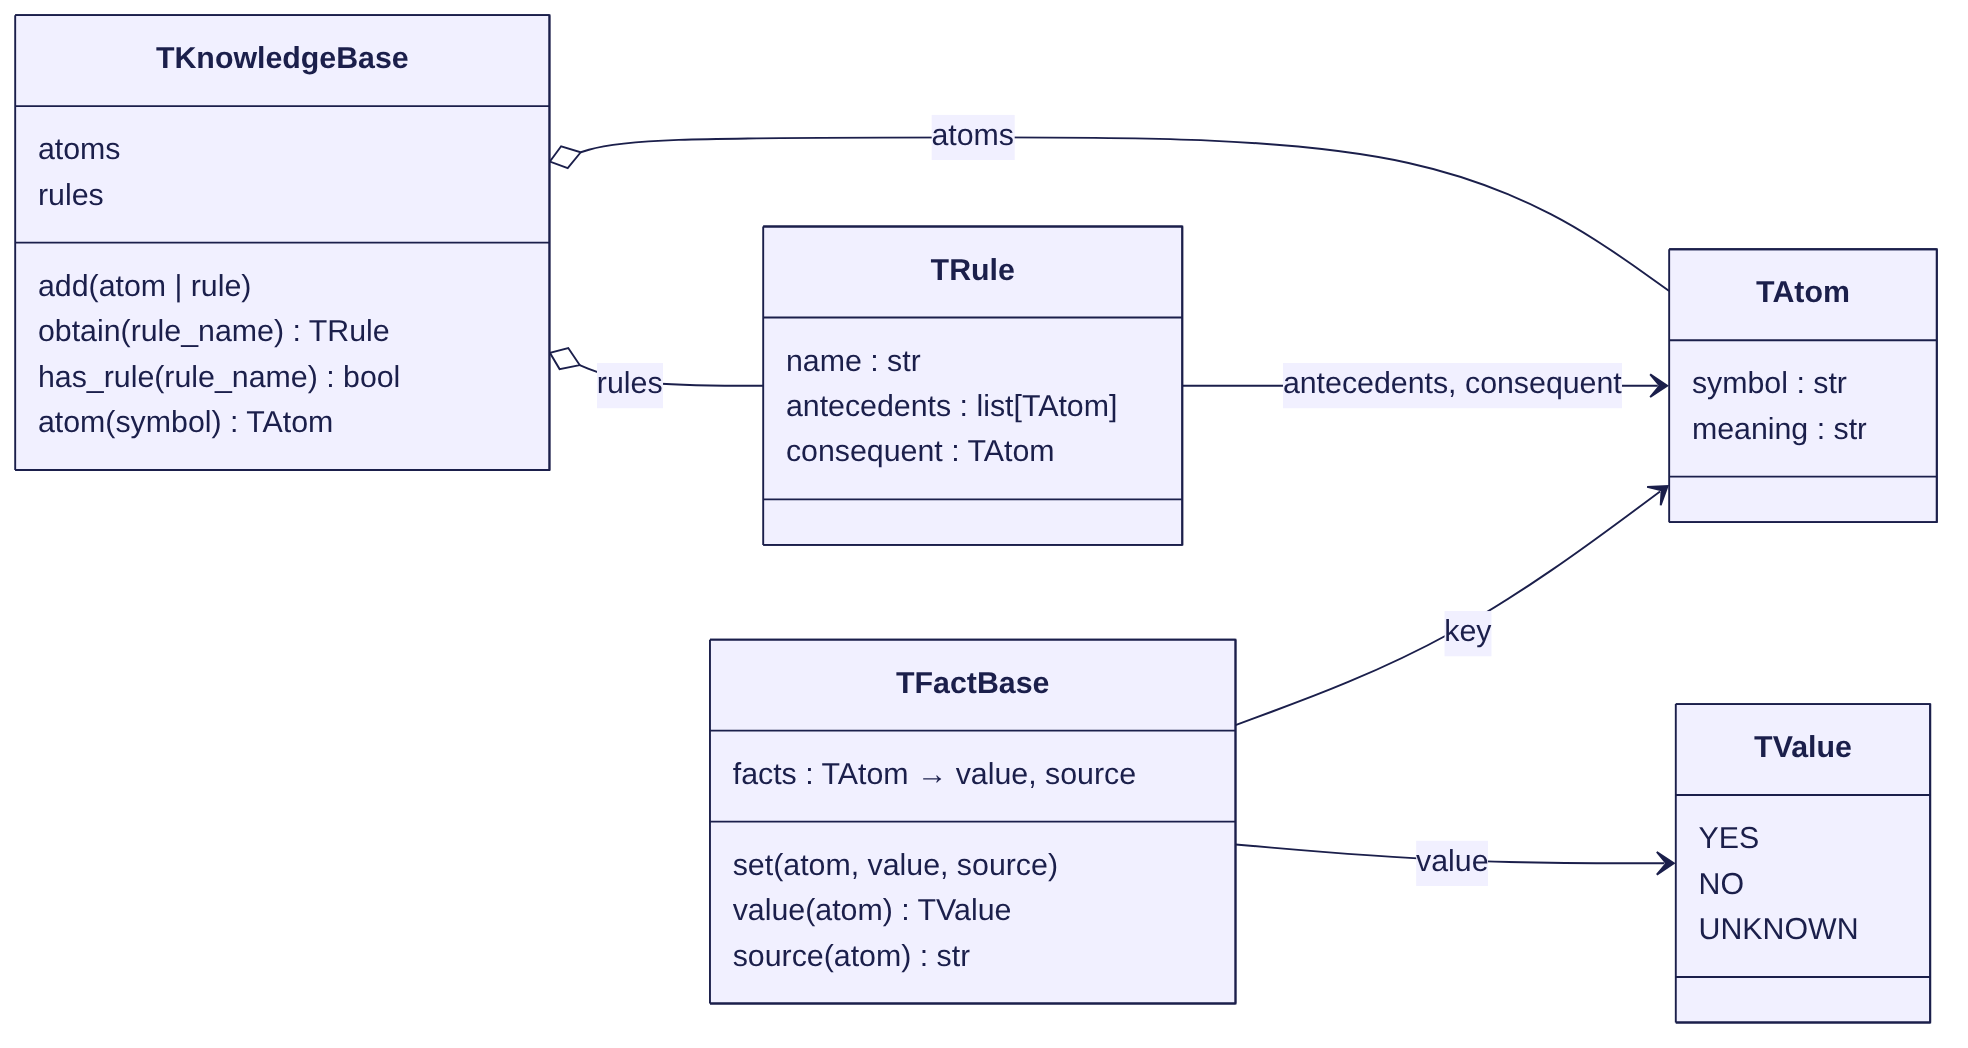

**Pruebas de la representación**

- **TAtom:** construir dos proposiciones, $\textcolor{#B389D6}{\textit{el animal tiene pelo}}$ y $\textcolor{#B389D6}{\textit{el suelo está mojado}}$, acceder a sus campos y verificar que:
  - dos `TAtom` construidos con el mismo `symbol` y `meaning` son **iguales** entre sí,
  - dos `TAtom` con `symbol` o `meaning` distintos son **distintos**,
  - un `TAtom` se puede usar como **clave** en un diccionario.
- **TRule:** construir la regla $\textcolor{#B389D6}{\textit{R1: si llueve, entonces el suelo está mojado}}$, verificar su identificador, sus antecedentes y su consecuente, y **mostrarla en lenguaje natural**.
- **TKnowledgeBase:**
  1. Crear una KB vacía.
  2. **Agregar primero las proposiciones** que usará la regla: $\textcolor{#B389D6}{\textit{está lloviendo}}$ y $\textcolor{#B389D6}{\textit{el suelo está mojado}}$.
  3. **Luego agregar la regla** $\textcolor{#B389D6}{\textit{R1: si llueve, entonces el suelo está mojado}}$.
  4. Verificar que la regla R1 quedó registrada en la KB, que al obtenerla por su identificador se recupera esa misma regla y que al buscar por su variable la proposición $\textcolor{#B389D6}{\textit{está lloviendo}}$ se recupera esa misma proposición.
  5. Verificar que intentar agregar una regla con proposiciones **no registradas** en la KB produce un error.
- **TFactBase:** agregar como hecho dado por el usuario que $\textcolor{#B389D6}{\textit{está lloviendo}}$ es verdadera, con el usuario como origen, y consultar su valor y su origen; verificar también el comportamiento con una proposición que *no* esté en la FB.

### TValue

Defina una clase `TValue` con las constantes: `YES`, `NO`, `UNKNOWN`.

In [ ]:
class TValue:
    """Los valores para una proposición atómica."""

### TAtom

Defina una clase `TAtom` que se pueda **comparar** y usar como clave de un diccionario. Dos `TAtom` son iguales si tienen el mismo `symbol` y el mismo `meaning`.

In [ ]:
class TAtom:
    """Una proposición atómica, con su variable y significado."""

    def __init__(self, symbol: str, meaning: str) -> None: ...

In [ ]:
# *COMPLETE* — prueba de TAtom

### TRule

Defina una clase `TRule`

In [ ]:
class TRule:
    """Una cláusula definida."""

    def __init__(self, name: str, antecedents: list[TAtom], consequent: TAtom) -> None: ...

    def __str__(self) -> str:
        """Representación en lenguaje natural de la regla."""

In [ ]:
# *COMPLETE* — prueba de TRule

### TKnowledgeBase

Defina una clase `TKnowledgeBase` que almacene **dos conjuntos** del dominio: las **proposiciones** (`TAtom`) y las **reglas** (`TRule`). Agreguen las funciones que consideren necesarios (p. ej. listar proposiciones o reglas).

In [ ]:
class TKnowledgeBase:
    """La base de conocimiento: proposiciones y cláusulas definidas.

    Almacena dos conjuntos del dominio: atoms, las proposiciones (TAtom),
    y rules, las reglas (TRule), que se identifican por su name.
    """

    def __init__(self) -> None: ...

    def add(self, item: TAtom | TRule) -> None:
        """Agregar una proposición o una regla.

        Al agregar una regla, sus antecedents y su consequent ya deben
        estar registrados en atoms.

        :param item: La proposición o la regla a agregar.
        :raises ValueError: Si la regla usa proposiciones no registradas.
        """

    def obtain(self, rule_name: str) -> TRule:
        """Recuperar una regla por su identificador.

        :param rule_name: El identificador de la regla.
        :return: La regla registrada con ese identificador.
        """

    def has_rule(self, rule_name: str) -> bool:
        """Conocer si un identificador de regla ya está registrado.

        :param rule_name: El identificador de la regla.
        :return: True si la regla está en la KB.
        """

    def atom(self, symbol: str) -> TAtom | None:
        """Recuperar una proposición por su symbol.

        La usarán la interfaz y la traducción de árboles a reglas.

        :param symbol: La variable de la proposición.
        :return: La proposición, o None si no está registrada.
        """

In [ ]:
# *COMPLETE* — prueba de TKnowledgeBase

### TFactBase

Defina una clase `TFactBase` que guarde en `facts` cada hecho con **tres** piezas: la proposición (`TAtom`), su **valor** (`TValue`) y su **origen** (`source`). 

In [ ]:
class TFactBase:
    """La base de hechos: proposiciones atómicas con su valor y origen.

    Guarda en facts, para cada atom (la clave), su value y su source:
    'user' si lo dio el usuario, o el identificador de la regla que lo dedujo.
    """

    def __init__(self) -> None: ...

    def set(self, atom: TAtom, value: TValue, source: str) -> None:
        """Agregar o actualizar un hecho.

        :param atom: La proposición.
        :param value: Su valor: YES, NO o UNKNOWN.
        :param source: 'user' o el identificador de la regla que lo dedujo.
        """

    def value(self, atom: TAtom) -> TValue:
        """Conocer el valor de un hecho.

        :param atom: La proposición.
        :return value: El valor del hecho.
        """

    def source(self, atom: TAtom) -> str | None:
        """Conocer el origen de un hecho.

        :param atom: La proposición.
        :return source: 'user', el identificador de la regla que dedujo
            el hecho, o None si el hecho no está en la FB.
        """

In [ ]:
# *COMPLETE* — prueba de TFactBase

## C. INFERENCIA

Implementen los dos algoritmos clásicos

### Forward chaining

Parte de los hechos y aplica reglas hasta que no se pueda deducir más. Deriva *todo* lo deducible (*dirigido por datos*).

**Implementación**

1. `applies(kb, fb, rule)`: indica si una regla se puede aplicar a la base de hechos.

   > **Idea.** Antes de aplicar una regla, el motor necesita saber si puede aplicarla **ahora**, si **ya nunca** podrá, o si todavía le **falta información**.

   > **Recuerde.** `UNKNOWN` en la FB es definitivo (*se sabe que no se sabe*): por eso un antecedente en `UNKNOWN` hace que la regla **ya no** pueda aplicarse.

2. `forward(kb, fb)`: la inferencia hacia adelante.

   > **Idea.** Parte de los hechos y aplica toda regla cuyos antecedentes ya sean `YES` y cuyo consecuente aún no esté en la FB, hasta que una pasada completa ya no agregue nada. Cada hecho nuevo guarda como origen **el identificador de la regla** que lo dedujo, para poder rastrear el *cómo*.

**Pruebe su implementación**

- **applies:**
  1. Cree una KB con **tres proposiciones** (`a`, `b`, `c`) y la regla `R: a` $\land$ `b` $\Rightarrow$ `c`.
  2. Cree **tres bases de hechos**, una por cada resultado esperado:
     - FB con `a = YES, b = YES` → `applies` debe dar `YES`.
     - FB con `a = YES, b = NO` → `applies` debe dar `NO`.
     - FB con `a = YES` (y `b` ausente) → `applies` debe dar `UNKNOWN`.
- **forward:**
  1. Con `R1: llueve` $\Rightarrow$ `suelo_mojado` y `llueve = YES`, la FB resultante debe contener `suelo_mojado = YES` con origen `R1`.
  2. Ideen un ejemplo con una deducción que requiera **más de una pasada** de forward chaining (una regla cuyo consecuente habilita otra regla) y verifiquen el resultado final.

In [ ]:
def applies(kb: TKnowledgeBase, fb: TFactBase, rule: TRule) -> TValue:
    """Conocer si una regla es aplicable a la base de hechos dada.

    :param kb: La base de conocimiento.
    :param fb: La base de hechos.
    :param rule: La regla a evaluar.
    :return: YES si la regla es aplicable ahora;
                    NO si ya no podrá aplicarse;
                    UNKNOWN si falta información.
    """

In [ ]:
def forward(kb: TKnowledgeBase, fb: TFactBase) -> TFactBase:
    """Conocer el resultado de la inferencia con razonamiento hacia adelante.

    :param kb: La base de conocimiento.
    :param fb: La base de hechos.
    :return: La base de hechos actualizada con los hechos inferidos;
        cada hecho nuevo tiene como origen el identificador de su regla.
    """

In [ ]:
# *COMPLETE* — prueba de applies y forward

### Backward chaining

Parte de una pregunta y busca reglas que la concluyan, preguntando al usuario cuando falta información. Deriva *sólo* lo necesario (*dirigido por objetivos*).

**Implementación**

1. `ask(p)`: le pide al usuario, con `input`, el valor de una proposición.

   > **Idea.** Es la forma en que el motor le pregunta al usuario lo que no puede deducir.

   `backward` usa esta función cuando encuentra una proposición que **no es consecuente de ninguna regla**.

2. `deduce(kb, p)`: devuelve las reglas de `kb` cuyo consecuente es `p`.

3. `backward(kb, fb, p)`: la inferencia hacia atrás.

   > **Idea.** Parte de una pregunta y trabaja **hacia atrás**: busca las reglas que concluyen `p` y convierte sus antecedentes en subpreguntas, de forma **recursiva**. Si ninguna regla logra concluir `p`, su valor es `UNKNOWN`. Solo toca lo necesario (*dirigido por objetivos*).

**Pruebe su implementación**

- **ask:** defina una proposición `tiene_pelo` y ejecute `ask(tiene_pelo)`. Verifique que:
  - se muestra al usuario el `meaning` de la proposición,
  - respuestas inválidas se rechazan y se vuelve a preguntar,
  - las respuestas `YES`, `NO` y `UNKNOWN` se aceptan y devuelven el `TValue` correcto.
- **deduce:** en una KB con dos reglas que concluyen `c`, `deduce` devuelve ambas; para una proposición que ningún consecuente concluye, devuelve lista vacía.
- **backward:**
  1. Con la KB `{R1: llueve` $\Rightarrow$ `suelo_mojado}` y la FB con `llueve = YES`, consultar `suelo_mojado` debe devolver `YES` con origen `R1`, **sin preguntar nada al usuario**.
  2. Con la KB de su ejemplo de varias pasadas y una FB vacía, consulten la última conclusión de la cadena y verifiquen el orden en que el motor hace las preguntas.

In [ ]:
def ask(p: TAtom) -> TValue:
    """Preguntar al usuario por el valor de una proposición atómica.

    Muestra el meaning de p y acepta YES, NO o UNKNOWN; insiste hasta
    recibir una respuesta válida.

    :param p: La proposición a preguntar.
    :return: El valor dado por el usuario (YES, NO o UNKNOWN).
    """

In [ ]:
def deduce(kb: TKnowledgeBase, p: TAtom) -> list[TRule]:
    """Conocer las reglas que permiten concluir una proposición atómica.

    :param kb: La base de conocimiento.
    :param p: La proposición a concluir.
    :return: Las reglas cuyo consecuente es p.
    """

In [ ]:
def backward(
    kb: TKnowledgeBase, fb: TFactBase, p: TAtom
) -> tuple[TValue, TFactBase]:
    """Conocer el resultado de la inferencia con razonamiento hacia atrás.

    :param kb: La base de conocimiento.
    :param fb: La base de hechos; se actualiza durante la búsqueda.
    :param p: La proposición que se quiere responder.
    :return: El valor de p y la base de hechos actualizada.
    """

In [ ]:
# *COMPLETE* — prueba de ask, deduce y backward

## D. EXPLICACIÓN E INTERFAZ

### Explicar el *cómo* de una conclusión

**Implementación**

1. `explain(kb, fb, p)`: explica el *cómo* de una conclusión.

   > **Idea.** Responde el **¿cómo?** de una conclusión: recorre los orígenes guardados en la FB desde `p` hasta llegar a los hechos que dio el usuario.

**Pruebe su implementación**

- **explain:** con `R1: llueve` $\Rightarrow$ `suelo_mojado` y `R2: suelo_mojado` $\land$ `hace_frio` $\Rightarrow$ `hay_hielo`, y los hechos `llueve = YES` y `hace_frio = YES`, apliquen `forward` y expliquen `hay_hielo`. Deben verse las dos reglas y los dos hechos del usuario.

In [ ]:
def explain(kb: TKnowledgeBase, fb: TFactBase, p: TAtom) -> str:
    """Explicar el cómo de una conclusión recorriendo los orígenes en la FB.

    :param kb: La base de conocimiento.
    :param fb: La base de hechos, con los orígenes.
    :param p: La proposición a explicar.
    :return: La cadena de justificación, con un nivel de sangría por regla.
    """

In [ ]:
# *COMPLETE* — prueba de explain

### Interfaz del SBC

La interfaz permite al usuario interactuar con el motor. Deben construirla **separando los dos subsistemas** del SBC.

**Implementación**

Completen las dos clases; pueden agregar los comandos que consideren necesarios.

1. `DevelopmentSubsystem`: el subsistema de desarrollo, para **construir** el conocimiento (proposiciones y reglas de la KB).
2. `QuerySubsystem`: el subsistema de consulta, para **usar** el conocimiento (hechos de la FB, `forward`, `backward` y `explain`).

**Pruebe su interfaz**

Ideen un escenario propio (distinto a Zookeeper) con **al menos 4 proposiciones y 5 reglas** y úsenlo para probar la interfaz. Escriban primero un párrafo corto que describa el escenario y luego muestren:

1. La KB construida *usando el subsistema de desarrollo*.
2. La FB inicial construida *usando el subsistema de consulta*.
3. El resultado de `forward`.
4. El **cómo** de al menos una conclusión.
5. Un ejemplo de `backward`.

In [ ]:
class DevelopmentSubsystem:
    """Subsistema de desarrollo: construir el conocimiento."""

    def __init__(self, kb: TKnowledgeBase) -> None: ...

    def add_atom(self) -> None:
        """Pedir symbol y meaning y registrar la proposición en la KB."""

    def add_rule(self) -> None:
        """Pedir name, antecedents y consequent y registrar la regla."""

    def show(self) -> None:
        """Mostrar las proposiciones y reglas registradas."""

    def reset(self) -> None:
        """Iniciar un nuevo conocimiento (vaciar la KB)."""

    def run(self) -> None:
        """Mostrar el menú y ejecutar comandos hasta que el usuario salga."""

In [ ]:
class QuerySubsystem:
    """Subsistema de consulta: usar el conocimiento."""

    def __init__(self, kb: TKnowledgeBase, fb: TFactBase) -> None: ...

    def add_fact(self) -> None:
        """Pedir symbol y valor y registrar el hecho en la FB."""

    def infer(self) -> None:
        """Ejecutar forward y mostrar los hechos recién deducidos."""

    def answer(self) -> None:
        """Pedir una proposición y responderla con backward."""

    def how(self) -> None:
        """Pedir una conclusión y mostrar su explicación con explain."""

    def show(self) -> None:
        """Mostrar la FB actual."""

    def reset(self) -> None:
        """Iniciar una nueva consulta (vaciar la FB sin tocar la KB)."""

    def run(self) -> None:
        """Mostrar el menú y ejecutar comandos hasta que el usuario salga."""

> *COMPLETE: describan su escenario de demostración.*

In [ ]:
# *COMPLETE*: prueba de la interfaz

## E. APRENDIENDO EL ÁRBOL

Escribir a mano todas las reglas de un experto es lento y costoso, y el experto no siempre sabe explicar lo que sabe. La alternativa es **aprender las reglas a partir de ejemplos**. un árbol de decisión permite construir las reglas aprendiendo de los ejemplos: elige el atributo **más importante**, divide los ejemplos según sus valores y repite en cada subconjunto hasta que sea puro. La importancia se mide con la **ganancia de información**:

$$Gain(A) = B\left(\frac{p}{p+n}\right) - Remainder(A), \qquad Remainder(A) = \sum_{k=1}^{d} \frac{p_k + n_k}{p + n}\, B\left(\frac{p_k}{p_k + n_k}\right)$$

### Árboles de decisión

Según el ejemplo visto en clase, usaremos el caso del restaurante: **¿esperar una mesa?**. Son 12 ejemplos descritos por 10 atributos y la decisión `will_wait`; los datos están en el archivo `restaurant.csv`.

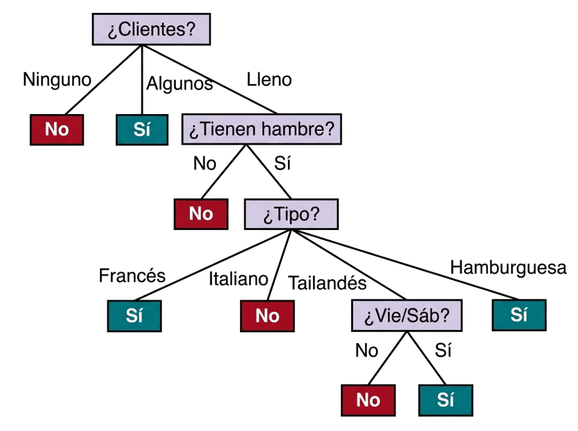

[YDF](https://ydf.readthedocs.io/) entrena árboles y bosques de decisión a partir de un `DataFrame`. El **modelo** CART construye un único árbol:

```python
model = ydf.CartLearner(
    label="will_wait",
    task=ydf.Task.CLASSIFICATION,
    # ... hiperparámetros
).train(examples)

model.plot_tree()           # el árbol, de forma gráfica
model.evaluate(examples)    # exactitud, matriz de confusión, ...
model.predict(examples)     # probabilidad de cada clase
model.label_classes()       # el orden de las clases en esas probabilidades
model.get_tree(0)           # el árbol, para recorrer sus nodos
```

Por defecto, ydf está pensado para conjuntos de datos grandes. Para que se comporte como árbol de decisión simple con solo 12 ejemplos, consulten la [documentación de `CartLearner`](https://ydf.readthedocs.io/en/latest/py_api/CartLearner/) y elijan el valor de estos hiperparámetros:

- `validation_ratio`: la fracción de ejemplos que se aparta para **podar** el árbol (la poda, sec. 19.3.4, está fuera del alcance de este laboratorio).
- `min_examples`: el número mínimo de ejemplos en un nodo.
- `min_vocab_frequency`: el número mínimo de veces que debe aparecer un valor categórico para no tratarlo como desconocido (`<OOD>`).

**Resuelva**

1. Entrenen un modelo con el conjunto de datos `restaurant`, justifiquen en un comentario el valor elegido para cada hiperparámetro y muestren el árbol y su exactitud sobre los mismos ejemplos.
2. Comparen el árbol aprendido con el del libro ¿qué atributos usa?, ¿cuál está en la raíz?, ¿qué atributos no aparecen?
3. ¿Qué condición quedó en la raíz? ¿Qué valores del atributo quedaron en cada rama y en qué se diferencia de la división del árbol del libro?
4. Prueben su modelo para el siguiente ejemplar. Completen los atributos faltantes como quieran.

   | Alt | Bar | Fri | Hun | Pat | Price | Rain | Res | Type | Est |
   |:-:|:-:|:-:|:-:|:-:|:-:|:-:|:-:|:-:|:-:|
   | ? | ? | ? | `no` | `full` | ? | ? | ? | ? | `0-10` |

   ¿Qué decide el árbol? ¿Es lo que haría una persona en esa situación? Si no lo es, ¿por qué el árbol decide así?

In [ ]:
# *COMPLETE*

> *COMPLETE*

# II. APLICACIÓN

Usarán su sistema basado en conocimiento (SBC) con conocimiento declarado (Zookeeper), con conocimiento aprendido y con la combinación de ambos.

## A. ZOOKEEPER: CONOCIMIENTO DECLARADO

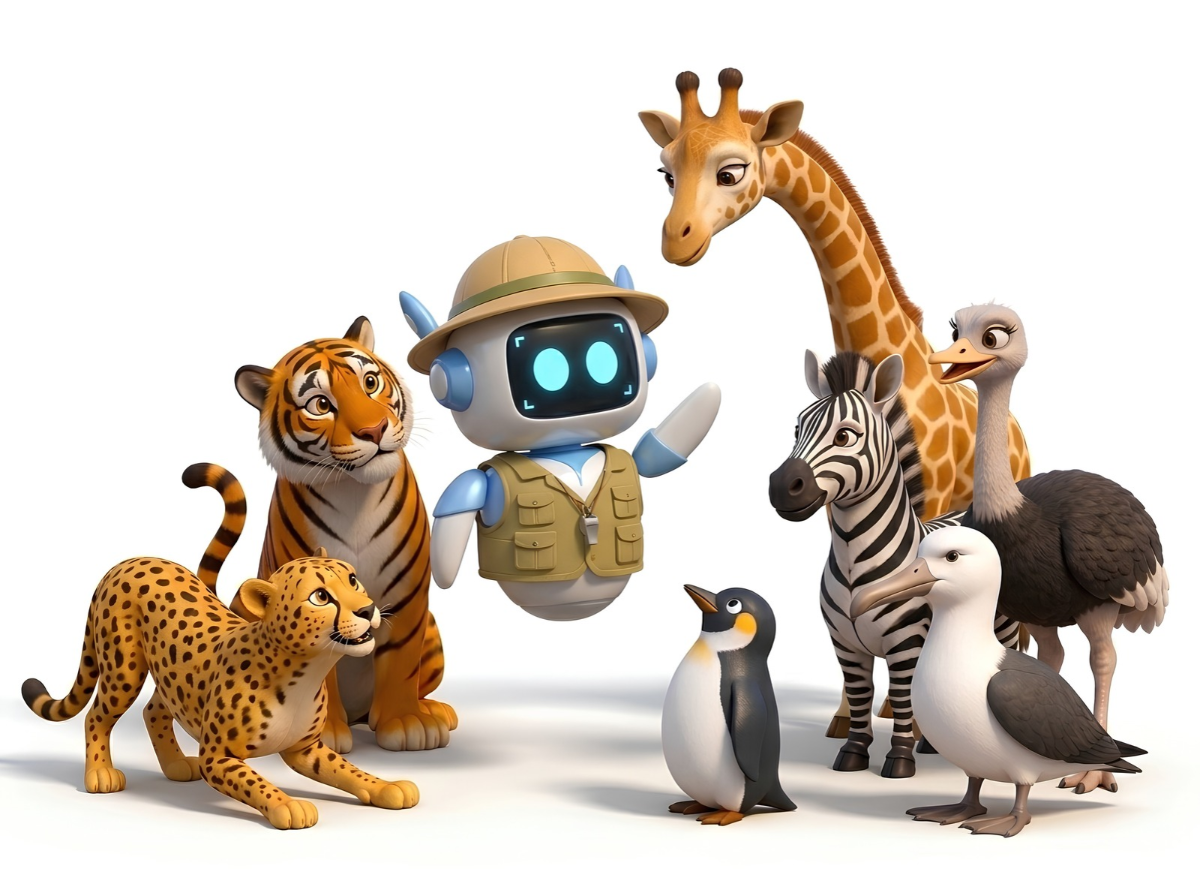

El caso **Zookeeper** (Winston, 1992) <cite data-cite="winston1992artificial"></cite> clasifica animales a partir de observaciones con 15 reglas escritas por un experto (revisen el documento `zookeeper.pdf`).

### Construcción de la base de conocimiento

Pasos:

1. **Identifiquen** las proposiciones atómicas relevantes del dominio (observaciones + categorías). Cada una tiene un `symbol` y un `meaning` claro.
2. **Expresen cada regla** del dominio como cláusula definida $(P_1 \land \dots \land P_n) \Rightarrow Q$, donde `Q` es típicamente una categoría más abstracta.
3. **Codifiquen la KB**: registren todas las proposiciones y las reglas en la KB.

Casos:

1. **Stretch**: Registren en una *base de hechos A* las observaciones del animal *Stretch*, apliquen `forward` sobre la *base de conocimiento* usando la *base de hechos A*, muestren la FB resultante y el **cómo** de la clasificación obtenida.
2. **Splashy**: Registren en *base de hechos B* las observaciones del animal *Splashy*. Apliquen `backward` con las hipótesis *avestruz*, *pingüino* y *albatros*, en ese orden, hasta que una se confirme; de Splashy no se sabe nada más, así que respondan `NO` a lo que el motor pregunte. Muestren la FB resultante y el **cómo** de la clasificación obtenida.

In [ ]:
# *COMPLETE* — construyan la KB y muéstrenla

In [ ]:
# *COMPLETE* — caso stretch

In [ ]:
# *COMPLETE* — caso splashy

### Preguntas al motor

1. ¿Qué se puede deducir con la *base de hechos B* usando `forward`? ¿Coincide con lo que encontró `backward` en el caso Splashy? ¿Cuál de los dos hizo menos trabajo?
2. ¿Cuál es el comportamiento del SBC si se le pregunta si un animal es un **leopardo**? ¿Por qué?
3. ¿Cuál es el comportamiento del SBC si se le pregunta si un animal es una **jirafa**? Con una FB vacía, respondan como si fuera Stretch y muestren el orden de las preguntas.
4. Repitan la pregunta anterior, pero respondan `UNKNOWN` a *"¿tiene pelo?"*. ¿Puede el motor concluir que es mamífero? ¿Qué papel cumple que haya dos reglas (Z1 y Z2) para la misma conclusión?
5. ¿Qué observaciones le faltan a Splashy para que el motor concluya *avestruz*? Si las tuviera, ¿qué concluiría `backward` con el orden de hipótesis dado y qué concluiría `forward`? ¿Por qué es peculiar el resultado?

In [ ]:
# *COMPLETE* — preguntas al motor

> *COMPLETE*

## B. ZOO: CONOCIMIENTO APRENDIDO

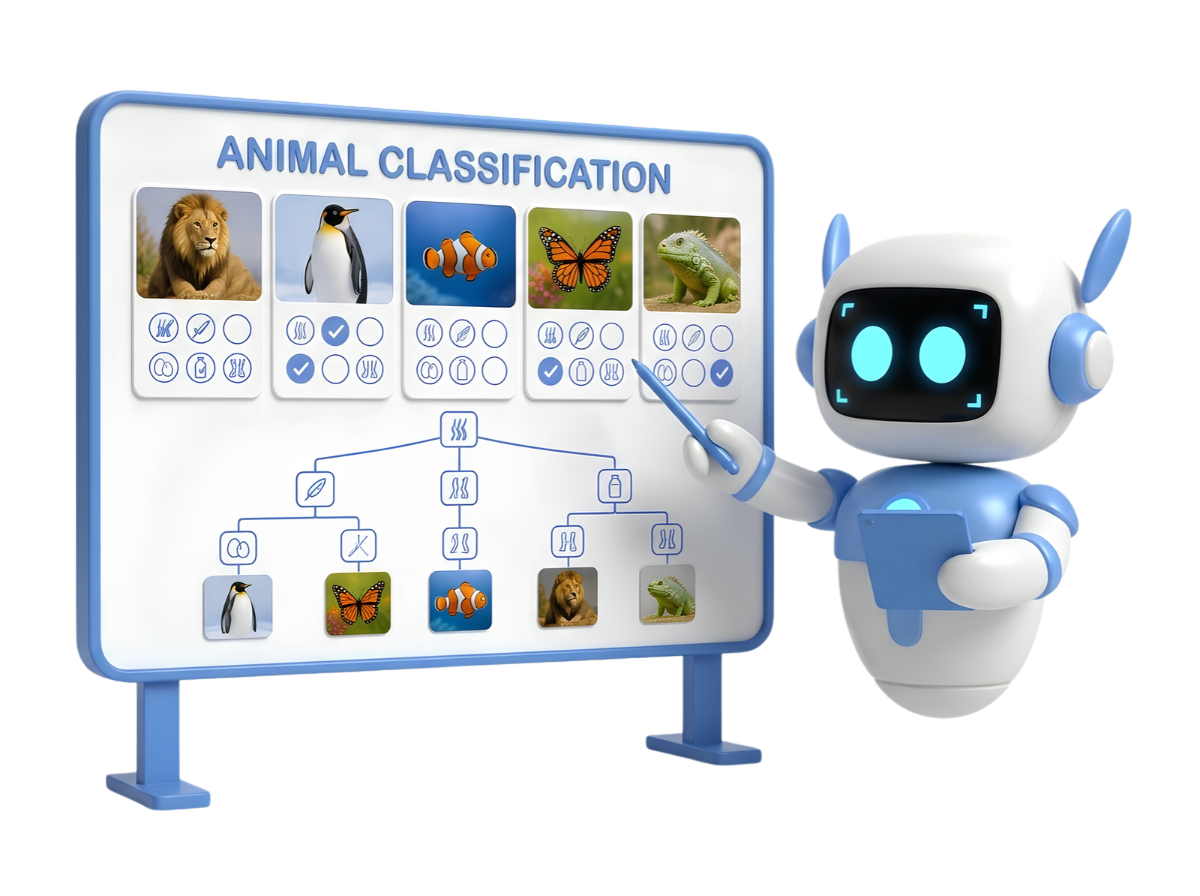

El conjunto de datos *Zoo* (Forsyth, 1990) <cite data-cite="forsyth1990zoo"></cite> describe 101 animales con 16 atributos y los clasifica en 7 tipos.

Los datos están en el archivo `zoo.csv`. Exploren la [página del conjunto en el repositorio UCI](https://archive.ics.uci.edu/dataset/111/zoo) para conocer qué significa cada atributo y qué valores toma.

Apliquen la metodología de ML vista en clase y responda:

1. ¿Qué atributo quedó en la raíz? ¿Qué reglas aprendidas se parecen a Zookeper? ¿En qué se diferencian?
2. ¿Qué punto de corte eligió el árbol para `legs` (si lo usa) y por qué tiene sentido tratarlo como número y no como categoría?
3. Traduzca el árbol de decisión a reglas ¿Cuántas reglas tiene la KB aprendida y cuántas tiene Zookeeper? ¿Cuál explica mejor sus conclusiones?

In [ ]:
# *COMPLETE* — formulación, entendimiento y preparación

In [ ]:
# *COMPLETE* — entrenamiento y prueba

In [ ]:
# *COMPLETE* — kb_aprendida

> *COMPLETE*

## C. BASE DE CONOCIMIENTO HÍBRIDA

1. Construyan una base de conocimiento híbrida reemplazando reglas de Zookeeper por las reglas **aprendidas**, de modo que concluyan las mismas proposiciones de mamífero y ave de su KB. Conserven las demás reglas.
2. Utilicen `backward` y una FB vacía, pregunten si el animal es una **jirafa** respondiendo como Stretch. ¿Qué preguntas hace ahora el motor? ¿Llega a la misma conclusión en una KB declarada? ¿Por qué? Muestren el *cómo* de la respuesta.
3. Un visitante describe un animal imaginario que **tiene plumas y da leche**. ¿Qué concluye la KB de Zookeeper? ¿Qué concluye la KB aprendida? ¿Detecta el SBC alguna contradicción? Relacionen la respuesta con la *hipótesis de amplitud*.
4. Comparen el enfoque **declarativo** y el de **aprendizaje** para construir la KB: costo de construcción, capacidad de explicar el *cómo*, qué pasa cuando aparecen nuevos ejemplos y cuándo usarían cada uno o la combinación.

In [ ]:
# *COMPLETE* — kb_hibrida y consulta de la jirafa

> *COMPLETE*

# III. RETROSPECTIVA

1. ¿Cuál fue el tiempo total invertido en el laboratorio por cada uno de ustedes? (Horas/Hombre)

2. ¿Cuál es el estado actual del laboratorio? ¿Por qué?

3. ¿Cuál consideran fue el mayor logro? ¿Por qué?

4. ¿Cuál consideran que fue el mayor problema técnico? ¿Qué hicieron para resolverlo?

5. ¿Qué hicieron bien como equipo? ¿Qué se comprometen a hacer para mejorar los resultados?